# PubChem and RDKit

Exercises from the ITMO course *Artificial Intelligence in a Chemist's Work*: retrieving compound properties from PubChem by name,
computing RDKit descriptors, and basic work with molecules (SDF files, atom indices, substructure search, formulas).
`data/molecule.sdf` was provided in the course and is not included.

In [ ]:
# !pip install pubchempy rdkit
import time
import pandas as pd
import pubchempy as pcp
from rdkit import Chem
from rdkit.Chem import Descriptors, Draw, rdMolDescriptors

## 1. Properties of compounds from PubChem

Names in `mols.csv` mix trivial names, IUPAC names, an abbreviation and a CAS number.

In [ ]:
input_df = pd.read_csv('data/mols.csv')
mol_names = input_df.iloc[:, 0].dropna().unique().tolist()

properties_to_get = ['SMILES', 'XLogP', 'MolecularWeight', 'Complexity', 'TPSA']
all_data = []

print(f"Searching PubChem for {len(mol_names)} compounds...")

for name in mol_names:
    success = False
    retries = 3
    while retries > 0 and not success:
        try:
            results = pcp.get_properties(properties_to_get, name, namespace='name')
            if results:
                res_dict = results[0]
                res_dict['Search_Term'] = name
                all_data.append(res_dict)
                success = True
            else:
                print(f"Not found: '{name}'")
                success = True
        except Exception as e:
            retries -= 1
            if retries == 0:
                print(f"Error while searching '{name}': {e}")
            else:
                time.sleep(1)

final_df = pd.DataFrame(all_data)
final_df.rename(columns={'SMILES': 'IsomericSMILES'}, inplace=True)
cols_order = ['Search_Term', 'CID', 'IsomericSMILES', 'XLogP', 'MolecularWeight', 'Complexity', 'TPSA']
final_df = final_df[[c for c in cols_order if c in final_df.columns]]

Searching PubChem for 10 compounds...


In [ ]:
final_df.rename(columns={'Search_Term': 'Molecule'}, inplace=True)
display(final_df)

,Molecule,CID,IsomericSMILES,XLogP,MolecularWeight,Complexity,TPSA
0,oleate,5460221,CCCCCCCC/C=C\CCCCCCCC(=O)[O-],7.9,281.5,228,40.1
1,citric acid,311,C(C(=O)O)C(CC(=O)O)(C(=O)O)O,-1.7,192.12,227,132.0
2,tetramethylethylenediamine,8037,CN(C)CCN(C)C,0.3,116.20,42,6.5
3,glyoxaline-5-alanine,6274,C1=C(NC=N1)C[C@@H](C(=O)O)N,-3.2,155.15,151,92.0
4,(2R)-2-amino-3-sulfanylpropanoic acid,5862,C([C@@H](C(=O)O)N)S,-2.5,121.16,75,64.3
5,BSA,25248,CC(=N[Si](C)(C)C)O[Si](C)(C)C,NaN,203.43,176,21.6
6,ethylene glycol,174,C(CO)O,-1.4,62.07,6,40.5
7,56-84-8,5960,C([C@@H](C(=O)O)N)C(=O)O,-2.8,133.10,133,101.0
8,(2S)-2-aminobutanedioic acid,5960,C([C@@H](C(=O)O)N)C(=O)O,-2.8,133.10,133,101.0
9,"3,5,3',5'-Tetramethylbenzidine",41206,CC1=CC(=CC(=C1N)C)C2=CC(=C(C(=C2)C)N)C,3.6,240.34,226,52.0


In [ ]:
final_df.to_csv('data/mols_with_properties.csv', index=False)
print("File saved: data/mols_with_properties.csv")

File saved: data/mols_with_properties.csv


## 2. Full set of RDKit descriptors for the same compounds

In [ ]:
df_mols = pd.read_csv('data/mols.csv')
smiles_by_name = dict(zip(final_df['Molecule'], final_df['IsomericSMILES']))   # SMILES from the PubChem search above

descriptor_data = []

for index, row in df_mols.iterrows():
    molecule_name = row['molecule']
    smiles = smiles_by_name.get(molecule_name)
    mol = Chem.MolFromSmiles(smiles) if smiles else None

    if mol is not None:
        current_mol_descriptors = {'Name': molecule_name, 'SMILES': smiles}
        for desc_name, desc_func in Descriptors.descList:
            try:
                current_mol_descriptors[desc_name] = desc_func(mol)
            except Exception:
                current_mol_descriptors[desc_name] = None
        descriptor_data.append(current_mol_descriptors)
    else:
        print(f"Could not build a molecule for: {molecule_name} (SMILES: {smiles})")

df_descriptors = pd.DataFrame(descriptor_data)
pd.options.display.max_columns = None
display(df_descriptors)

df_descriptors.to_csv('data/mol_descriptors.csv', index=False)
print('Descriptor table saved to data/mol_descriptors.csv')

,Name,SMILES,MaxAbsEStateIndex,MaxEStateIndex,MinAbsEStateIndex,MinEStateIndex,qed,SPS,MolWt,HeavyAtomMolWt,ExactMolWt,NumValenceElectrons,NumRadicalElectrons,MaxPartialCharge,MinPartialCharge,MaxAbsPartialCharge,MinAbsPartialCharge,FpDensityMorgan1,FpDensityMorgan2,FpDensityMorgan3,BCUT2D_MWHI,BCUT2D_MWLOW,BCUT2D_CHGHI,BCUT2D_CHGLO,BCUT2D_LOGPHI,BCUT2D_LOGPLOW,BCUT2D_MRHI,BCUT2D_MRLOW,AvgIpc,BalabanJ,BertzCT,Chi0,Chi0n,Chi0v,Chi1,Chi1n,Chi1v,Chi2n,Chi2v,Chi3n,Chi3v,Chi4n,Chi4v,HallKierAlpha,Ipc,Kappa1,Kappa2,Kappa3,LabuteASA,PEOE_VSA1,PEOE_VSA10,PEOE_VSA11,PEOE_VSA12,PEOE_VSA13,PEOE_VSA14,PEOE_VSA2,PEOE_VSA3,PEOE_VSA4,PEOE_VSA5,PEOE_VSA6,PEOE_VSA7,PEOE_VSA8,PEOE_VSA9,SMR_VSA1,SMR_VSA10,SMR_VSA2,SMR_VSA3,SMR_VSA4,SMR_VSA5,SMR_VSA6,SMR_VSA7,SMR_VSA8,SMR_VSA9,SlogP_VSA1,SlogP_VSA10,SlogP_VSA11,SlogP_VSA12,SlogP_VSA2,SlogP_VSA3,SlogP_VSA4,SlogP_VSA5,SlogP_VSA6,SlogP_VSA7,SlogP_VSA8,SlogP_VSA9,TPSA,EState_VSA1,EState_VSA10,EState_VSA11,EState_VSA2,EState_VSA3,EState_VSA4,EState_VSA5,EState_VSA6,EState_VSA7,EState_VSA8,EState_VSA9,VSA_EState1,VSA_EState10,VSA_EState2,VSA_EState3,VSA_EState4,VSA_EState5,VSA_EState6,VSA_EState7,VSA_EState8,VSA_EState9,FractionCSP3,HeavyAtomCount,NHOHCount,NOCount,NumAliphaticCarbocycles,NumAliphaticHeterocycles,NumAliphaticRings,NumAmideBonds,NumAromaticCarbocycles,NumAromaticHeterocycles,NumAromaticRings,NumAtomStereoCenters,NumBridgeheadAtoms,NumHAcceptors,NumHDonors,NumHeteroatoms,NumHeterocycles,NumRotatableBonds,NumSaturatedCarbocycles,NumSaturatedHeterocycles,NumSaturatedRings,NumSpiroAtoms,NumUnspecifiedAtomStereoCenters,Phi,RingCount,MolLogP,MolMR,fr_Al_COO,fr_Al_OH,fr_Al_OH_noTert,fr_ArN,fr_Ar_COO,fr_Ar_N,fr_Ar_NH,fr_Ar_OH,fr_COO,fr_COO2,fr_C_O,fr_C_O_noCOO,fr_C_S,fr_HOCCN,fr_Imine,fr_NH0,fr_NH1,fr_NH2,fr_N_O,fr_Ndealkylation1,fr_Ndealkylation2,fr_Nhpyrrole,fr_SH,fr_aldehyde,fr_alkyl_carbamate,fr_alkyl_halide,fr_allylic_oxid,fr_amide,fr_amidine,fr_aniline,fr_aryl_methyl,fr_azide,fr_azo,fr_barbitur,fr_benzene,fr_benzodiazepine,fr_bicyclic,fr_diazo,fr_dihydropyridine,fr_epoxide,fr_ester,fr_ether,fr_furan,fr_guanido,fr_halogen,fr_hdrzine,fr_hdrzone,fr_imidazole,fr_imide,fr_isocyan,fr_isothiocyan,fr_ketone,fr_ketone_Topliss,fr_lactam,fr_lactone,fr_methoxy,fr_morpholine,fr_nitrile,fr_nitro,fr_nitro_arom,fr_nitro_arom_nonortho,fr_nitroso,fr_oxazole,fr_oxime,fr_para_hydroxylation,fr_phenol,fr_phenol_noOrthoHbond,fr_phos_acid,fr_phos_ester,fr_piperdine,fr_piperzine,fr_priamide,fr_prisulfonamd,fr_pyridine,fr_quatN,fr_sulfide,fr_sulfonamd,fr_sulfone,fr_term_acetylene,fr_tetrazole,fr_thiazole,fr_thiocyan,fr_thiophene,fr_unbrch_alkane,fr_urea
0,oleate,CCCCCCCC/C=C\CCCCCCCC(=O)[O-],10.212964,10.212964,0.220396,-0.914234,0.320154,11.250000,281.460,248.196,281.248604,118,0,0.041384,-0.550172,0.550172,0.041384,0.750000,1.200000,1.700000,16.365132,10.078069,1.910107,-2.011759,2.091558,-2.208711,5.634971,-0.305341,2.425550,3.066158,233.572721,14.891059,13.370692,13.370692,9.770056,8.618738,8.618738,5.706297,5.706297,3.642703,3.642703,2.340077,2.340077,-0.790000,22676.463752,19.210000,16.264915,17.210000,125.209420,9.901065,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.0,70.44235,38.524930,5.969305,0.000000,9.901065,5.969305,0.0,0.000000,0.000000,96.815240,0.000000,12.152040,0.0,0.000000,5.106527,0.000000,0.0,0.000000,5.969305,4.794537,0.000000,96.815240,12.152040,0.000000,0.000000,0.0,40.13,5.969305,9.901065,0.0,6.420822,0.0,19.262465,64.208216,0.000000,0.000000,19.075777,0.000000,0.0,0.000000,10.212964,10.212964,0.000000,-0.914234,0.000000,20.898914,2.256059,0.000000,0.833333,20,0,2,0,0,0,0,0,0,0,0,0,2,0,2,0,15,0,0,0,0,0,15.622451,0,4.77380,84.4590,1,0,0,0,0,0,0,0,1,1,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,2,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,11,0
1,citric acid,C(C(=O)O)C(CC(=O)O)(C(=O)O)O,10.315556,10.315556,1.144213,-2.738426,0.427421,10.846154,192.123,184.059,192.027003,74,0,0.336419,-0.481139,0.481139,0.336419,0.

Descriptor table saved to data/mol_descriptors.csv


## 3. A molecule from an SDF file: SMILES, atom numbering, substructure search

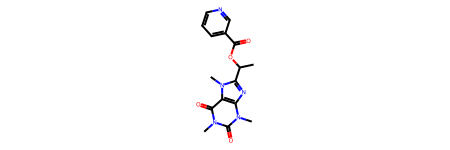

In [ ]:
mo = Chem.MolFromMolFile('data/molecule.sdf')
mo

In [ ]:
Chem.MolToSmiles(mo)

'CC(OC(=O)c1cccnc1)c1nc2c(c(=O)n(C)c(=O)n2C)n1C'

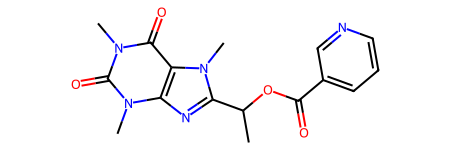

In [ ]:
mo = Chem.MolFromSmiles('CC(OC(=O)c1cccnc1)c1nc2c(c(=O)n(C)c(=O)n2C)n1C')
mo

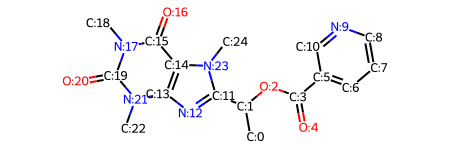

In [ ]:
for atom in mo.GetAtoms():
    atom.SetProp("molAtomMapNumber", str(atom.GetIdx()))
Draw.MolToFile(mo, 'mol_with_prop.png')
mo

In [ ]:
patt = Chem.MolFromSmarts('ccO')
mo.HasSubstructMatch(patt)

True

## 4. Short exercises

Atoms matching an aromatic C–C–O fragment:

In [ ]:
mol = Chem.MolFromSmiles('CCC(COC(=O)C1=CC(=C(C(=C1)OC)OC)OC)(C2=CC=CC=C2)NC')
patt = Chem.MolFromSmarts('ccO')
mol.GetSubstructMatch(patt)

(8, 9, 17)

Number of heavy atoms and molecular formula of 3,3′,5,5′-tetramethylbenzidine:

In [ ]:
smiles = 'CC1=CC(=CC(=C1N)C)C2=CC(=C(C(=C2)C)N)C'
mol = Chem.MolFromSmiles(smiles)
print(mol.GetNumHeavyAtoms())

18


In [ ]:
print(rdMolDescriptors.CalcMolFormula(mol))

C16H20N2


Molecular weight and logP for a list of SMILES:

In [ ]:
smiles_list = ['CC(C)O', 'CC(F)(Cl)Br', 'CC(=O)O', 'C1=CC=CC=C1']
for smiles in smiles_list:
    mol = Chem.MolFromSmiles(smiles)
    print(f"Molecule: {smiles}, Molecular Weight: {Descriptors.MolWt(mol)}, LogP: {Descriptors.MolLogP(mol)}")

Molecule: CC(C)O, Molecular Weight: 60.096000000000004, LogP: 0.38710000000000006
Molecule: CC(F)(Cl)Br, Molecular Weight: 161.401, LogP: 2.2633
Molecule: CC(=O)O, Molecular Weight: 60.05200000000001, LogP: 0.09089999999999993
Molecule: C1=CC=CC=C1, Molecular Weight: 78.11399999999999, LogP: 1.6866
